### Parcial Inferencia Estadistica y Reconocimiento de Patrones.
#### Alumnas: Gonzalez Camila Belén - Parallela Luciana Sol.



#### Importamos librerias:

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,ConfusionMatrixDisplay,f1_score, precision_score, recall_score,roc_curve, auc

from sklearn.preprocessing import OrdinalEncoder 

#### Realizamos un analisis exploratorio para ver:
1. Nombres de las columnas.
2. Cuantas filas tenemos y el total de datos.
3. Cuantos valores nulos tenemos.

In [6]:
#Importamos los datos 
datos = pd.read_csv(r"C:\Users\ASUS\OneDrive\Desktop\Bases de datos inferencia\base_primer_parcial.csv")
datos.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### Evaluamos si hay valores nulos:

In [7]:
#Vemos la cantidad de filas y columnas
#datos.shape  #Nos da 14999 filas y 10 columnas
datos.isna().sum() # Nos da 0, indicando que no hay valores nulos
datos.dropna()
datos.shape   #No se redujeron las filas, por tanto no hay valores nulos

(14999, 10)

In [8]:
#Nombres de las columnas
datos.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'sales', 'salary'],
      dtype='object')

#### Definimos las clases (target = "left"). 
#### Teniendo en cuenta que queremos predecir si el empleado abandonará o no la empresa, definimos a la clase 1 como "abandona" y la clase 0 como "no abandona".


In [9]:
# SEPARAMOS EN X e Y
Y = datos.loc[ : ,  ["left"]]                # la variable Y representa a las clases

X = datos.iloc[:, : ]                        # Creamos la variable X que contiene todas las columnas

X.drop(columns=["left"],inplace = True)      #Eliminamos la columna "left" que representa a las clases que queremos predecir


#### Convertimos las variables categóricas a numéricas de la variable X. Luego, mostramos qué representa cada valor numérico en referencia a los otros valores.
#### De la columna "sales" tenemos:
  IT -> 0
  RandD -> 1
  accounting -> 2
  hr -> 3
  management -> 4
  marketing -> 5
  product_mng -> 6
  sales -> 7
  support -> 8
  technical -> 9

#### De la columna "salary"  tenemos: 
  high -> 0
  low -> 1
  medium -> 2

In [10]:
#Convertimos variables categóricas a numéricas en X
enconder = OrdinalEncoder()
X[["sales", "salary"]] = enconder.fit_transform(X[["sales", "salary"]]) 

for col, cats in zip(["sales", "salary"], enconder.categories_):
    print(f"Columna: {col}")
    for i, cat in enumerate(cats):
        print(f"  {cat} -> {i}")

Columna: sales
  IT -> 0
  RandD -> 1
  accounting -> 2
  hr -> 3
  management -> 4
  marketing -> 5
  product_mng -> 6
  sales -> 7
  support -> 8
  technical -> 9
Columna: salary
  high -> 0
  low -> 1
  medium -> 2


#### Analizamos si las clases estan desbalanceadas. Podemos observar que hay un desbalance muy notorio. La clase correspondiente a 0-"No abandona" representa el 76% de los datos, y clase 1 - "abandona" el porcentaje restante.

In [38]:
print(Y.value_counts())
print(Y.value_counts(normalize=True))  # Proporción de cada clase

left
0       11428
1        3571
Name: count, dtype: int64
left
0       0.761917
1       0.238083
Name: proportion, dtype: float64


### Chequeamos si las variables están correlacionadas entre sí y si lo están, qué tanto. Podemos observar que las variables "avarage_montly_hours" y "number_project" son las que más correlacionadas están entre sí. Luego podemos decir que la correlación entre las otras variables es muy baja o casi nula.

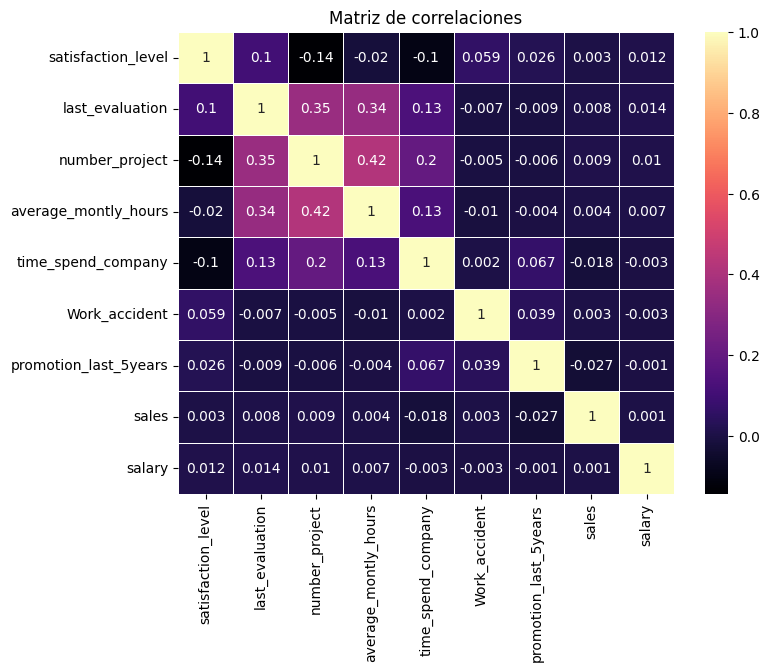

                       satisfaction_level  last_evaluation  number_project  \
satisfaction_level                  1.000            0.105          -0.143   
last_evaluation                     0.105            1.000           0.349   
number_project                     -0.143            0.349           1.000   
average_montly_hours               -0.020            0.340           0.417   
time_spend_company                 -0.101            0.132           0.197   
Work_accident                       0.059           -0.007          -0.005   
promotion_last_5years               0.026           -0.009          -0.006   
sales                               0.003            0.008           0.009   
salary                              0.012            0.014           0.010   

                       average_montly_hours  time_spend_company  \
satisfaction_level                   -0.020              -0.101   
last_evaluation                       0.340               0.132   
number_project    

In [11]:
matriz_correlacion = round(X.corr(),3)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacion, annot=True, cmap='magma', linewidths=0.5)
plt.title("Matriz de correlaciones")
plt.show()
print(matriz_correlacion)

### Hacemos un histrograma por variable para evaluar su distribución. Podemos decir que no poseen una distribución normal.

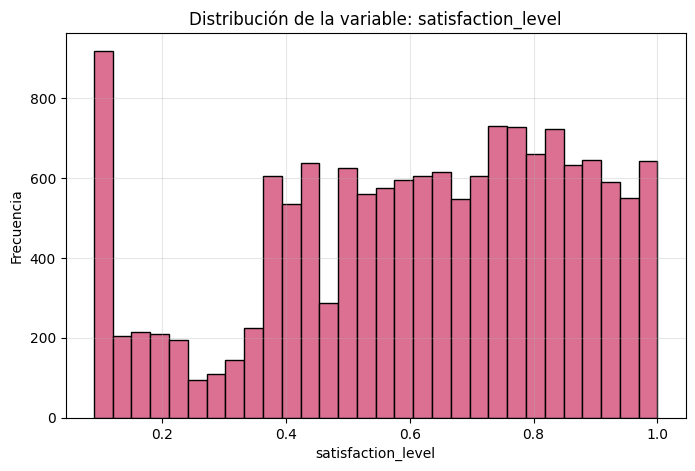

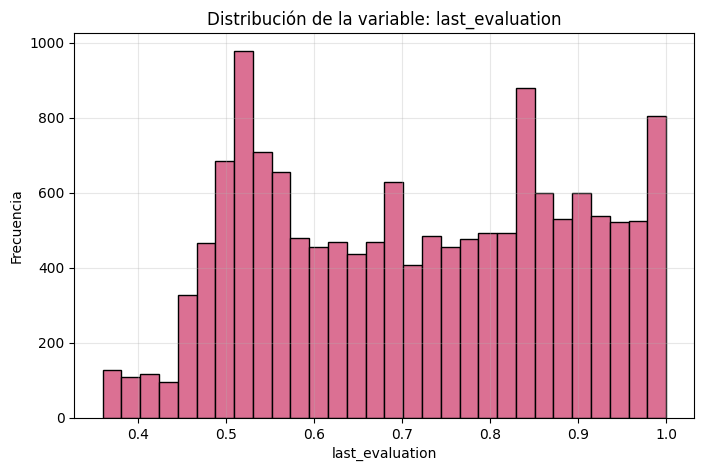

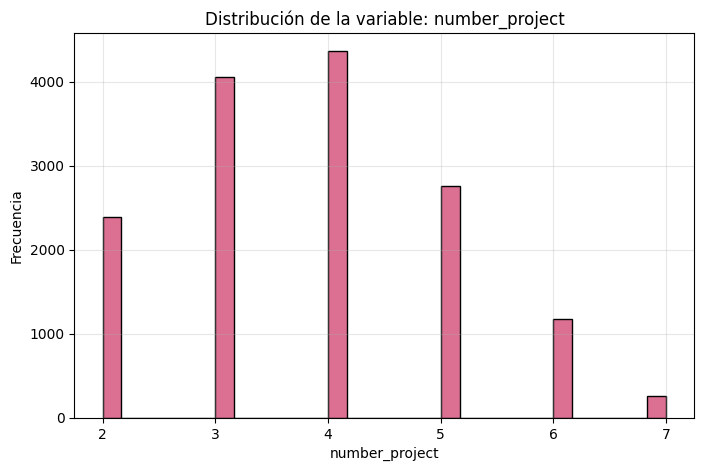

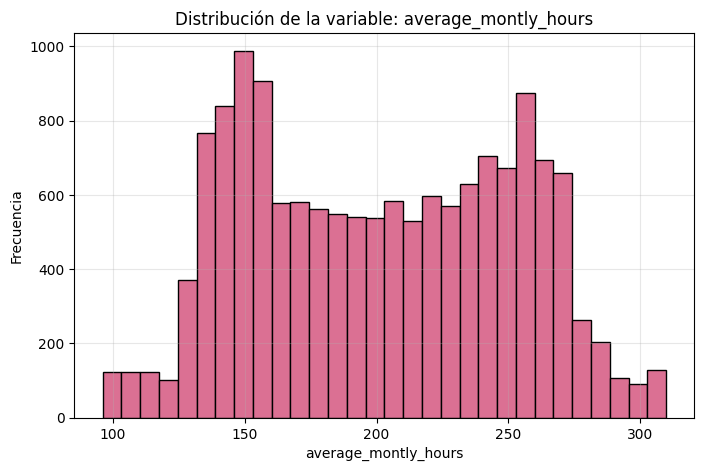

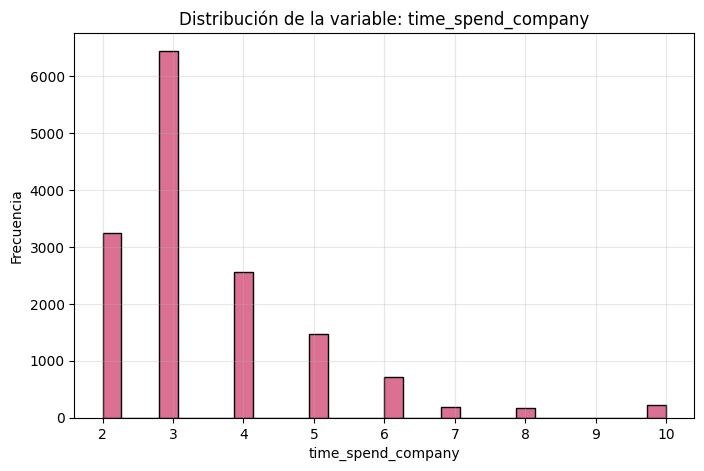

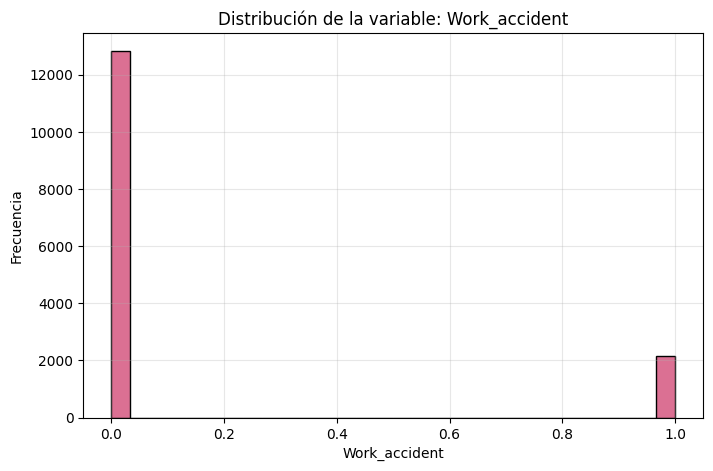

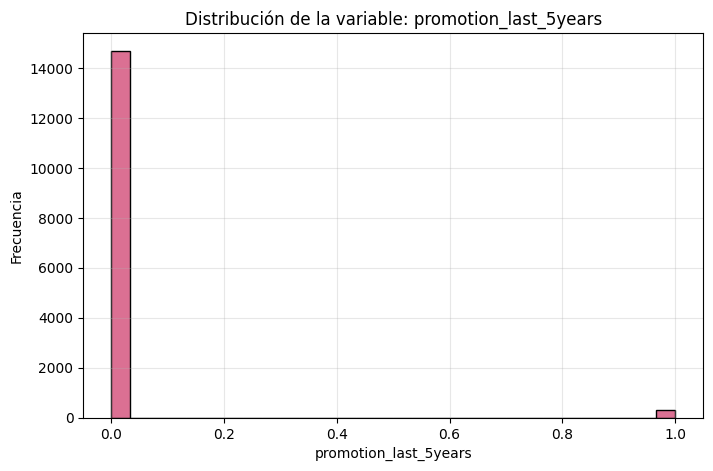

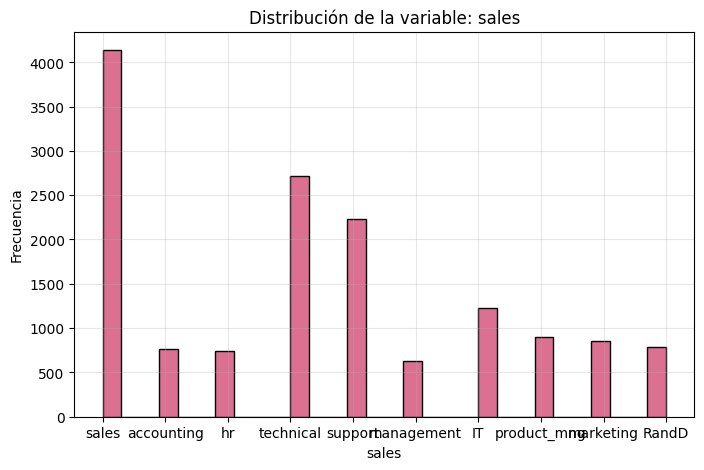

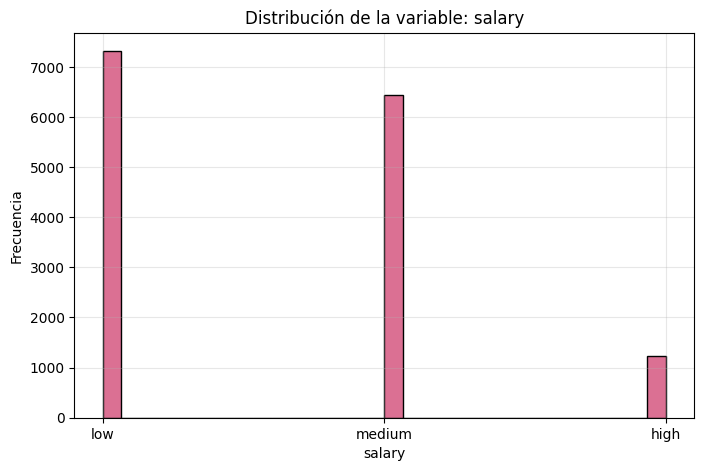

In [12]:
for i in X.columns:
    plt.figure(figsize=(8,5))
    plt.hist(datos[i], bins=30, color='palevioletred', edgecolor='black')
    plt.title(f"Distribución de la variable: {i}")
    plt.xlabel(i)
    plt.ylabel("Frecuencia")
    plt.grid(True, alpha=0.3)
    plt.show()

### Comenzamos con la aplicación de los algoritmos.
### Primero estandarizamos las variables.

In [13]:
#ESTANZARIZAMOS LOS DATOS
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [14]:
#Debido al desbalance, usamos stratify, muy importante para que en el conjunto de entrenamiento y prueba haya representacion de todas las clases
X_train, X_test, Y_train, Y_test = train_test_split(X_scaled, Y, test_size=0.2, random_state=42,stratify=Y)

### El primer algoritmo que aplicamos es la Máquina de Soporte Vectorial.

Con c = 1 tenemos un f1-score de 0.98 para la clase 0 y 0.73 para la clase 1
Con c = 200 tenemos un f1-score de 0.98 para la clase 0 y 0.95 para la clase 1
con c = 100 tenemos un f1-score de 0.98 para la clase 0 y 0.95 para la clase 1
con c= 120 tenemos un f1-score de 0.99 para la clase 0 y 0.95 para la clase 1  -- hemos decidido quedarnos con este

Hemos probado otros kernels, como "poly" o "linear" pero fueron ineficientes en la prediccion 


c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVC Accuracy
: 0.9773333333333334

Reporte de clasificacion del modelo SVM:
                precision    recall  f1-score   support

           0       0.98      0.99      0.99      2286
           1       0.96      0.94      0.95       714

    accuracy                           0.98      3000
   macro avg       0.97      0.97      0.97      3000
weighted avg       0.98      0.98      0.98      3000



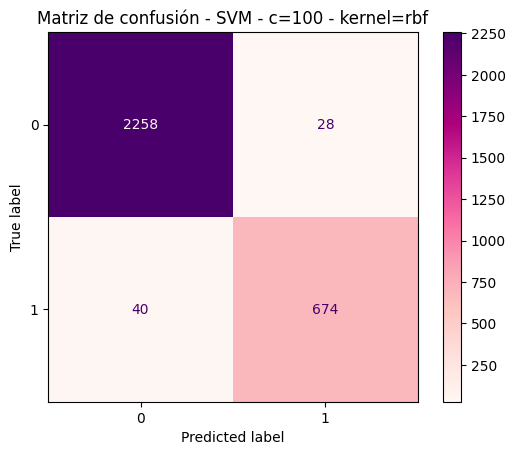

In [15]:

# IMPLEMENTAMOS LA MAQUINA DE SOPORTE VECTORIAL
svc_soft= SVC(kernel = "rbf", C = 120)     
svc_soft.fit(X_train, Y_train)
svc_pred = svc_soft.predict(X_test)
print(f"SVC Accuracy\n:",accuracy_score(Y_test,svc_pred))
print(f"\nReporte de clasificacion del modelo SVM:\n ", classification_report(Y_test, svc_pred))

matriz = confusion_matrix(Y_test, svc_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=svc_soft.classes_)
display.plot(cmap=plt.cm.RdPu) 
plt.title(f"Matriz de confusión - SVM - c=100 - kernel=rbf")
plt.show()


--------------------------------------------------------------------------------------

### A continuación ponemos los algoritmos de Naive Bayes, Análisis del Discrimante lineal y Análisis del Discriminante Cuadrático en funcionamiento y evaluamos sus métricas, para ver que tan bien predicen los modelos. 

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


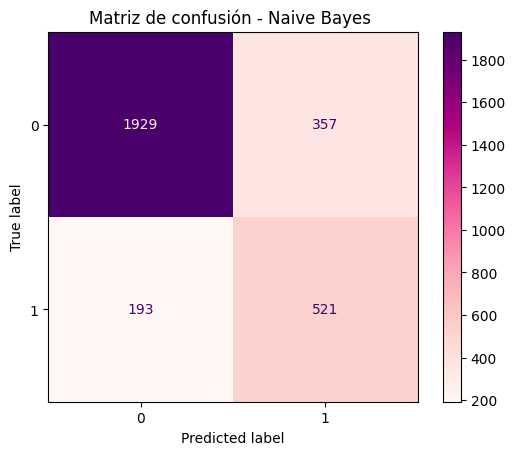

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


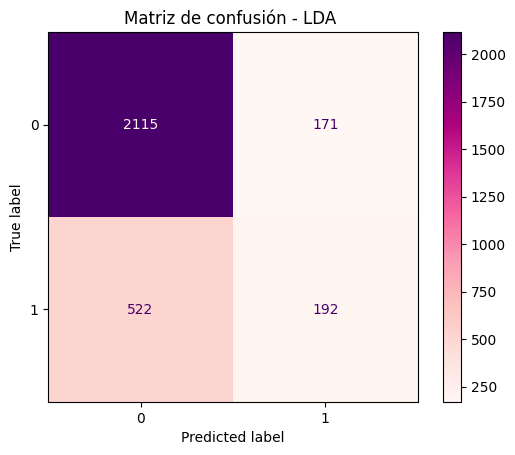

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


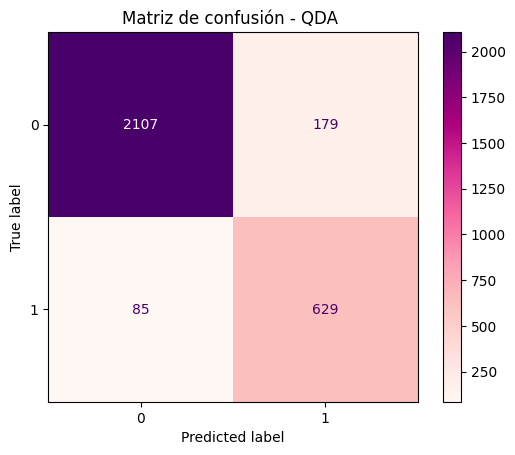

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


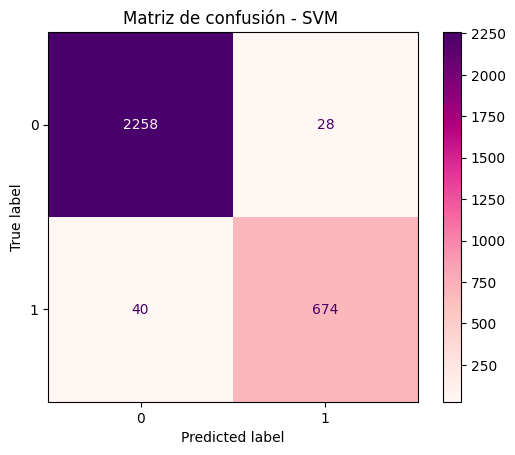

        Modelo  Accuracy  Precision    Recall  F1-Score
3          SVM  0.977333   0.977243  0.977333  0.977267
2          QDA  0.912000   0.917726  0.912000  0.913794
0  Naive Bayes  0.816667   0.833922  0.816667  0.822699
1          LDA  0.769000   0.737045  0.769000  0.739593


In [ ]:
modelos = {
    'Naive Bayes': GaussianNB(),
    'LDA': LinearDiscriminantAnalysis(),
    'QDA': QuadraticDiscriminantAnalysis(),
    'SVM' : SVC(kernel = "rbf", C = 120)
}

resultados = []

for nombre, modelo in modelos.items():
    modelo. fit(X_train, Y_train)
    y_pred = modelo.predict(X_test)

    resultados .append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(Y_test, y_pred),
        'Precision': precision_score(Y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(Y_test, y_pred, average='weighted', zero_division=0),
        'F1-Score': f1_score(Y_test, y_pred, average='weighted', zero_division=0)
    })
    matriz = confusion_matrix(Y_test, y_pred)
    from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Convertir los resultados en un DataFrame
resultados_df = pd.DataFrame(resultados)

# Mostrar la tabla ordenada por accuracy (por ejemplo)
print(resultados_df.sort_values(by='Accuracy', ascending=False))
    

### Graficamos la curva ROC para ver el rendimiento de los clasificadores, ya que nos permite evaluar la capacidad de los modelos para distinguir entre las clases y poder concluir cual clasifica mejor.

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConve

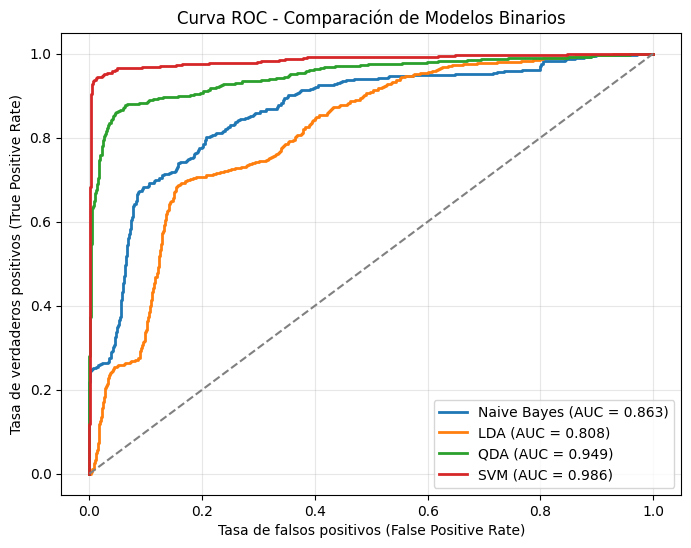

In [17]:
modelos = {
    'Naive Bayes': GaussianNB(),
    'LDA': LinearDiscriminantAnalysis(),
    'QDA': QuadraticDiscriminantAnalysis(),
    'SVM': SVC(kernel='rbf', C=100, probability=True) # Aseguramos que SVM pueda predecir probabilidades
}

plt.figure(figsize=(8,6))

for nombre, modelo in modelos.items():
    modelo.fit(X_train, Y_train)
    
    # Para obtener probabilidades (necesarias para la curva ROC)
    if hasattr(modelo, "predict_proba"):
        y_scores = modelo.predict_proba(X_test)[:, 1]
    else:
        y_scores = modelo.decision_function(X_test)
    
    fpr, tpr, _ = roc_curve(Y_test, y_scores)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {roc_auc:.3f})")

# Línea base (clasificador aleatorio)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('Tasa de falsos positivos (False Positive Rate)')
plt.ylabel('Tasa de verdaderos positivos (True Positive Rate)')
plt.title('Curva ROC - Comparación de Modelos Binarios')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


#### PCA
### Ahora implementamos el análisis de componentes principales para poder ver si la reducción de la dimensionalidad de las variables, mejora el rendimiento de los algoritmos mencionados anteriormente. 

In [18]:
modelo_pca = PCA()
modelo_pca.fit(X_scaled)
X_pca= modelo_pca.transform(X_scaled)

In [19]:
#VOLVEMOS A SEPARAR LOS DATOS DE ENTRAMIENTO DEL TEST PERO CON X DEL PCA
X_pca_train, X_pca_test, y_pca_train, y_pca_test = train_test_split(X_pca,Y, test_size=0.2, random_state=42,stratify=Y)

In [20]:
#Los pesos o "loadings" de cada variable en cada componente principal.
influencia_variable = pd.DataFrame(
    modelo_pca.components_.T,  # transponemos para que las variables estén en filas
    columns=[f'PC{i+1}' for i in range(len(modelo_pca.components_))],
    index=X.columns
)

print(influencia_variable)

                            PC1       PC2       PC3       PC4       PC5  \
satisfaction_level    -0.087608  0.792905 -0.011602  0.042895 -0.185765   
last_evaluation        0.507068  0.332793 -0.092227  0.023524 -0.113750   
number_project         0.578769 -0.101359 -0.036333 -0.026315  0.034856   
average_montly_hours   0.548950  0.105122 -0.087334 -0.005314 -0.058586   
time_spend_company     0.313164 -0.301713  0.380618 -0.023495  0.141661   
Work_accident         -0.019310  0.355620  0.404665 -0.295690  0.331581   
promotion_last_5years  0.009710  0.071082  0.728171  0.022360  0.138022   
sales                  0.006284  0.072648 -0.370362 -0.483834  0.705317   
salary                 0.017595  0.106771 -0.079923  0.821162  0.548971   

                            PC6       PC7       PC8       PC9  
satisfaction_level    -0.227331  0.336216 -0.277911  0.291871  
last_evaluation       -0.086653  0.073546  0.708216 -0.309265  
number_project         0.091415 -0.196830  0.006095  0.77

  Componente  Varianza explicada  Varianza acumulada
0        PC1            0.203371            0.203371
1        PC2            0.125397            0.328768
2        PC3            0.119169            0.447938
3        PC4            0.111245            0.559183
4        PC5            0.110136            0.669319
5        PC6            0.105466            0.774785
6        PC7            0.093919            0.868704
7        PC8            0.070394            0.939099
8        PC9            0.060901            1.000000


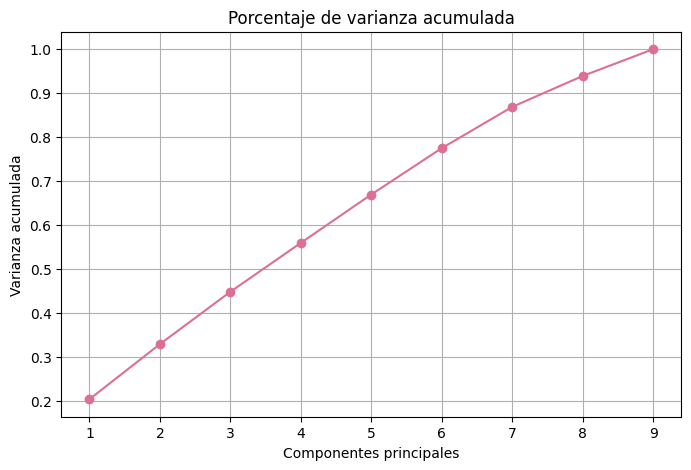

In [21]:
#Calcular varianza explicada y acumulada
varianza_explicada = modelo_pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

# Crear tabla con pandas
tabla_varianza = pd.DataFrame({
    'Componente': [f'PC{i+1}' for i in range(len(varianza_explicada))],
    'Varianza explicada': varianza_explicada,
    'Varianza acumulada': varianza_acumulada
})

# Mostrar la tabla
print(tabla_varianza)

# Gráfico de la varianza acumulada
plt.figure(figsize=(8,5))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada,
         marker='o', color='palevioletred')
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.grid(True)
plt.title('Porcentaje de varianza acumulada')
plt.xlabel('Componentes principales')
plt.ylabel('Varianza acumulada')
plt.show()

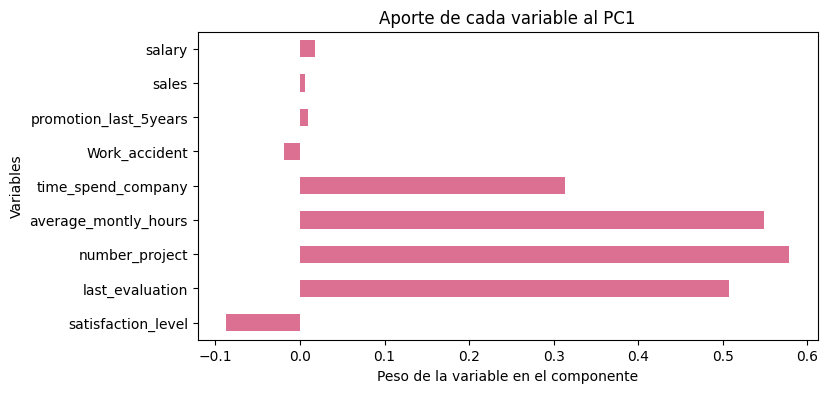

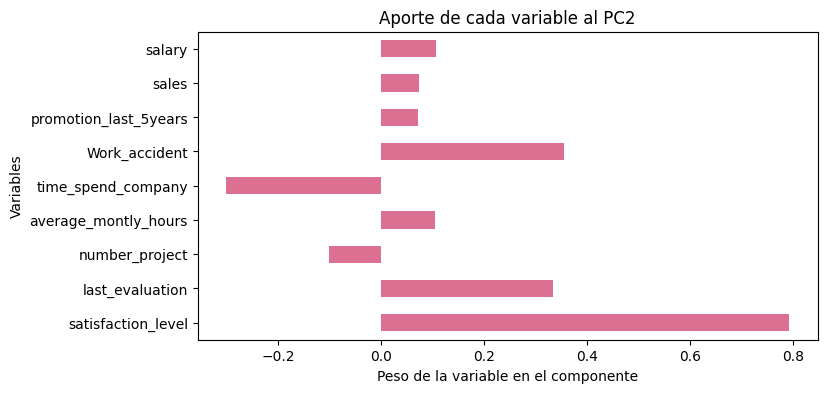

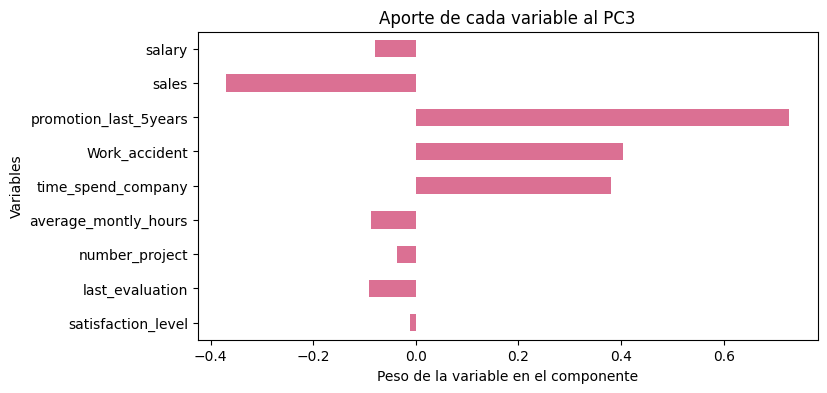

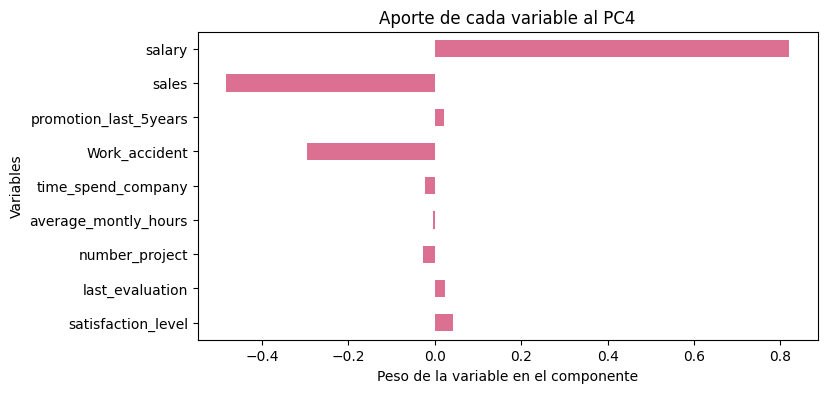

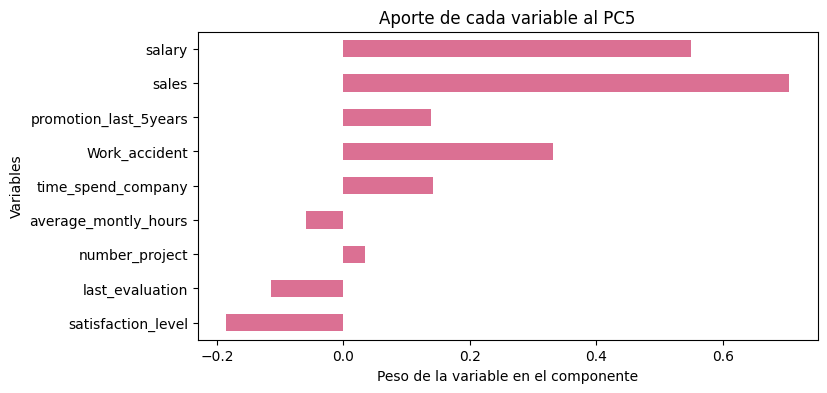

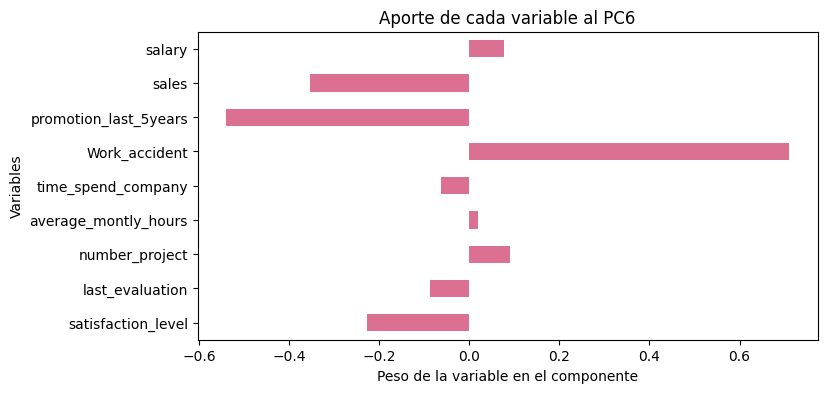

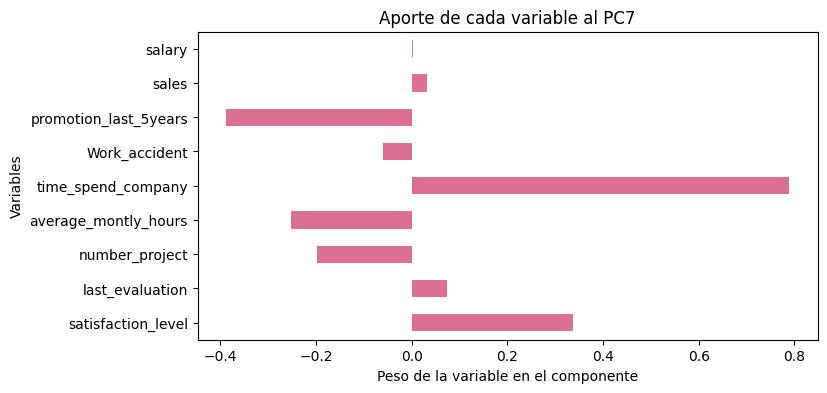

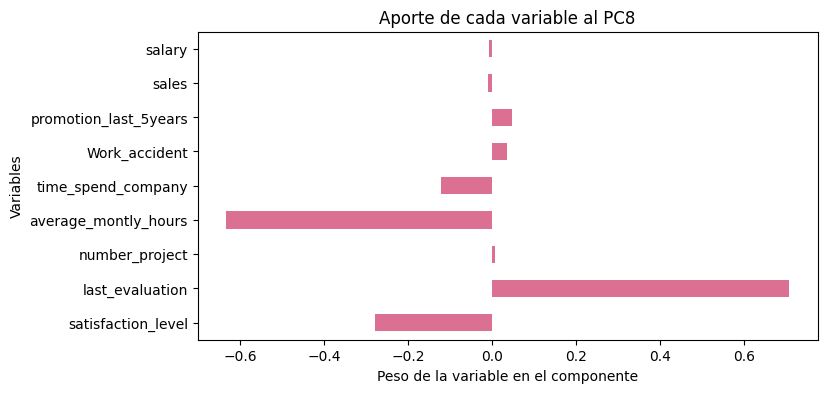

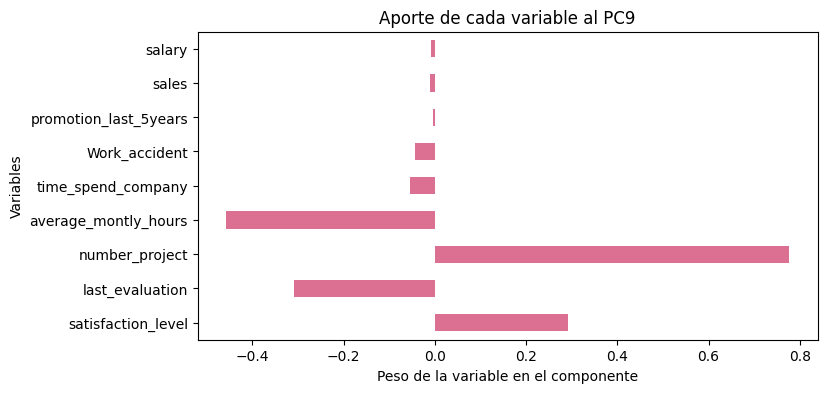

In [22]:
for pc in influencia_variable.columns: 
    plt.figure(figsize=(8, 4))
    influencia_variable[pc].plot(kind='barh', color='palevioletred')
    plt.title(f'Aporte de cada variable al {pc}')
    plt.ylabel('Variables')
    plt.xlabel('Peso de la variable en el componente')
    #plt.tight_layout()
    plt.show()

### Ceamos una matriz de correlación para comprobar la independencia total entre las variables una vez aplicado el PCA.

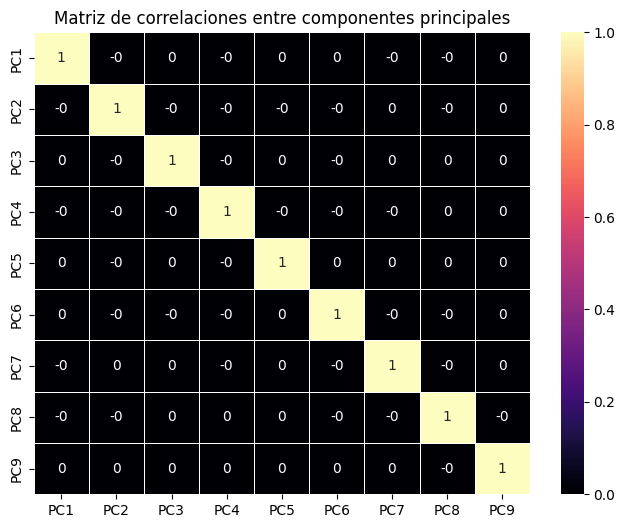

     PC1  PC2  PC3  PC4  PC5  PC6  PC7  PC8  PC9
PC1  1.0 -0.0  0.0 -0.0  0.0  0.0 -0.0 -0.0  0.0
PC2 -0.0  1.0 -0.0 -0.0 -0.0 -0.0  0.0 -0.0  0.0
PC3  0.0 -0.0  1.0 -0.0  0.0 -0.0  0.0  0.0  0.0
PC4 -0.0 -0.0 -0.0  1.0 -0.0 -0.0 -0.0  0.0  0.0
PC5  0.0 -0.0  0.0 -0.0  1.0  0.0  0.0  0.0  0.0
PC6  0.0 -0.0 -0.0 -0.0  0.0  1.0 -0.0 -0.0  0.0
PC7 -0.0  0.0  0.0 -0.0  0.0 -0.0  1.0 -0.0  0.0
PC8 -0.0 -0.0  0.0  0.0  0.0 -0.0 -0.0  1.0 -0.0
PC9  0.0  0.0  0.0  0.0  0.0  0.0  0.0 -0.0  1.0


In [23]:

X_pca_df = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(X_pca.shape[1])])

# Matriz de correlación
matriz_correlacion = round(X_pca_df.corr(),3)

# Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacion, annot=True, cmap='magma', linewidths=0.5)
plt.title("Matriz de correlaciones entre componentes principales")
plt.show()

print(matriz_correlacion)

-----------------------------------------------------------------------------------------------

#### Una vez analizadas las varianzas explicadas, hemos decidido quedarnos con 7 componentes que representan aproximadamente un 87% de variabilidad de los datos. Volvemos a aplicar los modelos de Naive Bayes, LDA, QDA y SVM para analizar si hay alguna modificación a la hora de predecir. 

In [24]:
modelo_pca7 = PCA(n_components=7)
modelo_pca7.fit(X_scaled)
X_pca7= modelo_pca7.transform(X_scaled)

#VOLVEMOS A SEPARAR LOS DATOS DE ENTRAMIENTO DEL TEST PERO CON X DEL PCA
X_pca7_train, X_pca7_test, y_pca7_train, y_pca7_test = train_test_split(X_pca7,Y, test_size=0.2, random_state=42,stratify=Y)

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


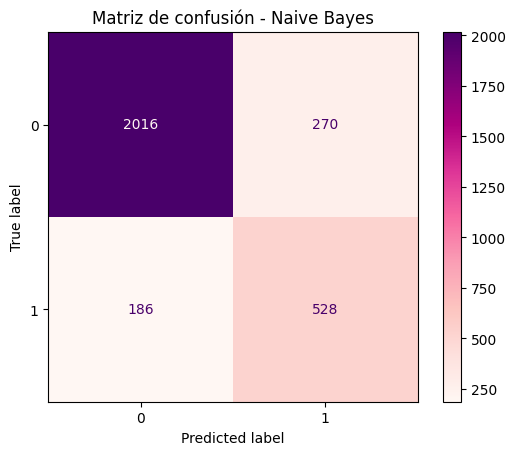

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


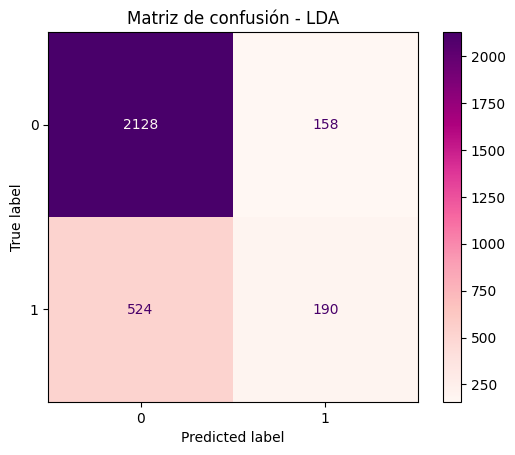

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


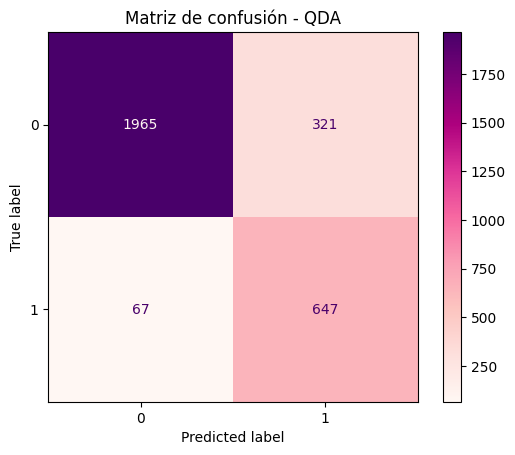

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


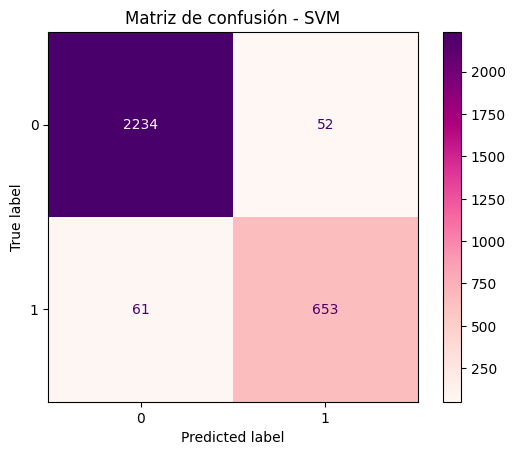

        Modelo  Accuracy  Precision    Recall  F1-Score
3          SVM  0.962333   0.962192  0.962333  0.962251
2          QDA  0.870667   0.895951  0.870667  0.876628
0  Naive Bayes  0.848000   0.855109  0.848000  0.850800
1          LDA  0.772667   0.741381  0.772667  0.741918


In [25]:
modelos = {
    'Naive Bayes': GaussianNB(),
    'LDA': LinearDiscriminantAnalysis(),
    'QDA': QuadraticDiscriminantAnalysis(),
    'SVM': SVC(kernel='rbf', C=100)

}

resultados = []

for nombre, modelo in modelos.items():
    modelo. fit(X_pca7_train, y_pca7_train)
    y_pred7_pca = modelo.predict(X_pca7_test)

    resultados .append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_pca_test, y_pred7_pca),
        'Precision': precision_score(y_pca_test, y_pred7_pca, average='weighted', zero_division=0),
        'Recall': recall_score(y_pca_test, y_pred7_pca, average='weighted', zero_division=0),
        'F1-Score': f1_score(y_pca_test, y_pred7_pca, average='weighted', zero_division=0)
    })
    matriz = confusion_matrix(y_pca7_test, y_pred7_pca)
    display = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=modelo.classes_)
    display.plot(cmap=plt.cm.RdPu) 
    plt.title(f"Matriz de confusión - {nombre}")
    plt.show()

# Convertir los resultados en un DataFrame
resultados_df = pd.DataFrame(resultados)

# Mostrar la tabla ordenada por accuracy (por ejemplo)
print(resultados_df.sort_values(by='Accuracy', ascending=False))
    

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConve

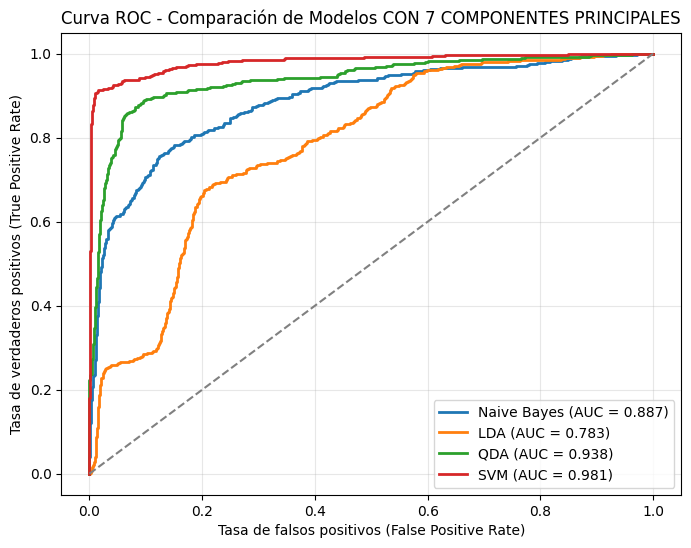

In [26]:
modelos = {
    'Naive Bayes': GaussianNB(),
    'LDA': LinearDiscriminantAnalysis(),
    'QDA': QuadraticDiscriminantAnalysis(),
    'SVM': SVC(kernel='rbf', C=100, probability=True) # Aseguramos que SVM pueda predecir probabilidades
}

plt.figure(figsize=(8,6))

for nombre, modelo in modelos.items():
    modelo.fit(X_pca7_train, y_pca7_train)
    
    # Para obtener probabilidades (necesarias para la curva ROC)
    if hasattr(modelo, "predict_proba"):
        y_scores = modelo.predict_proba(X_pca7_test)[:, 1]
    else:
        y_scores = modelo.decision_function(X_pca7_test)
    
    fpr, tpr, _ = roc_curve(y_pca7_test, y_scores)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {roc_auc:.3f})")

# Línea base (clasificador aleatorio)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('Tasa de falsos positivos (False Positive Rate)')
plt.ylabel('Tasa de verdaderos positivos (True Positive Rate)')
plt.title('Curva ROC - Comparación de Modelos CON 7 COMPONENTES PRINCIPALES')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

Hemos intentado graficar la frontera de decision del SVM, sin embargo, debido a la cantidad de variables y de datos, ha sido en vano, pues el gráfico no permitía ver reflejadas adecuadamente las clases debido al solapamiento de datos y el overplotting provocado. 

Finalmente podemos concluir que el mejor algoritmo para la clasificación entre "abandona" y "no abandona", es la máquina de soporte vectorial, la cual ha arrojado los mejores resultados, alcanzando un 98% de exactitud, precisión, recall y f1-score. Si bien el PCA nos puede ayudar con la reducción de dimensionalidad para la toma de decisiones más acertadas, trabajando con menor cantidad de datos, ese no siempre es el caso. Mientras que la SVM sin el PCA arrojó un resultado de AUC (área bajo la curva) de 98,6%, el modelo con el PCA aplicado, utilizando 7 PCs, arrojó un AUC = 98,1%. De esta manera, su resultado es menos eficiente. Es por eso que podemos decir que el modelo SVM predice mejor sin la aplicación PCA.